In [157]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [158]:
df = pd.read_csv('placement.csv')


In [159]:
df.sample(5).head()

,Unnamed: 0,cgpa,iq,placement
24,24,4.7,121.0,0
63,63,6.3,128.0,1
6,6,5.7,143.0,0
15,15,5.1,176.0,0
81,81,5.4,107.0,0


In [160]:
df.describe()

,Unnamed: 0,cgpa,iq,placement
count,100.000000,100.000000,100.000000,100.000000
mean,49.500000,5.991000,123.580000,0.500000
std,29.011492,1.143634,39.944198,0.502519
min,0.000000,3.300000,37.000000,0.000000
25%,24.750000,5.075000,101.500000,0.000000
50%,49.500000,6.000000,127.500000,0.500000
75%,74.250000,6.900000,149.000000,1.000000
max,99.000000,8.500000,233.000000,1.000000


# Steps

0. Preprocess + EDA + Feature Selection
1. Extract input and output cols
2. Scale the values
3. Train test split
4. Train the model
5. Evaluate the model/model selection
6. Deploy the model

In [161]:
# Preprocessing

df.info()
print()

print('Data Shape :',df.shape)  # shape = row x col

print()
df = df[['cgpa', 'iq', 'placement']]

df.head(5) 

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB

Data Shape : (100, 4)



,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Generic fa

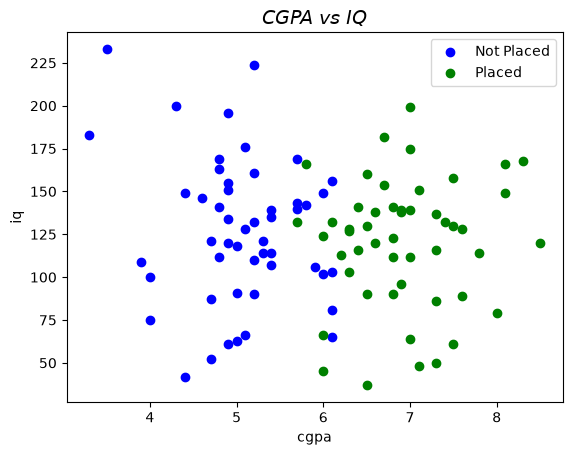

In [162]:
plt.title('CGPA vs IQ', fontfamily='cursive', fontsize=14, fontstyle='italic')
plt.scatter(df[df['placement'] == 0]['cgpa'], df[df['placement'] == 0]['iq'], color='blue', label='Not Placed')
plt.scatter(df[df['placement'] == 1]['cgpa'], df[df['placement'] == 1]['iq'], color='green', label='Placed')

plt.xlabel('cgpa')
plt.ylabel('iq')
plt.legend()
plt.show()

In [163]:
# Extract input and output cols

# # Dependent Variable (columes or features) 
X = df.iloc[:, :-1]  ## 2-D Tensor
X.head()

# # Independent Variable (colume or feature)
y = df.iloc[:, -1]   ## 1-D Tensor
y.head()

0    1
1    0
2    0
3    1
4    0
Name: placement, dtype: int64

In [164]:
# Train test split

from sklearn.model_selection import train_test_split

# train_test_split(X, y, test_size = 0.2)
# or 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.1, random_state=40)

In [165]:
# Scale the values
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()  # Mean = 0 and std = 1

**StandardScaler** standardizes data to a mean of 0 and a standard deviation ($\sigma$) of 1. It has no fixed bounded range (like 0 to 1), though most values fall between -3 and +3. Under the Empirical Rule, a standard deviation of 1 indicates that ~68% of the data lies close to the mean (within $\pm 1\sigma$).

In [166]:
X_train = scaler.fit_transform(X_train)
X_train

array([[-0.78524968,  0.12992785],
       [-0.18560447,  0.47750554],
       [-0.69958608,  0.94921812],
       [-0.01427727,  0.03061994],
       [-0.52825888, -0.39143868],
       [-2.32719452,  1.49541163],
       [ 0.41404074, -2.12932713],
       [-0.01427727,  0.65129439],
       [-0.78524968, -1.40934478],
       [-0.69958608, -0.31695775],
       [ 1.09934956, -0.16799588],
       [ 0.75669515, -0.66453544],
       [ 2.12731278, -0.06868797],
       [-0.87091329, -0.11834193],
       [ 0.84235875,  1.89264328],
       [-1.7275493 , -1.18590198],
       [ 1.09934956, -1.80657642],
       [-0.61392248, -0.04386099],
       [-0.95657689,  0.80025625],
       [-0.95657689,  1.81816234],
       [ 0.49970434, -0.06868797],
       [ 0.84235875,  0.40302461],
       [-1.04224049,  0.45267856],
       [ 0.67103155,  0.00579296],
       [ 0.32837714,  0.45267856],
       [-0.01427727, -1.93071131],
       [-0.27126807,  0.42785158],
       [ 0.92802235,  0.70094834],
       [ 0.49970434,

In [167]:
X_test = scaler.fit_transform(X_test)
X_test

array([[ 0.93648381, -1.21407754],
       [-1.21489791,  1.1309622 ],
       [ 0.68338008, -0.08608374],
       [-0.83524231,  1.33875053],
       [ 0.93648381,  0.86380578],
       [ 1.44269127,  0.21075674],
       [-1.08834605,  0.09202055],
       [ 0.30372448, -1.92649467],
       [-1.46800164,  0.44822911],
       [ 0.30372448, -0.85786897]])

In [168]:
# Trian the model

from sklearn.linear_model import LogisticRegression

clf = LogisticRegression() 

In [169]:
clf.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [170]:
y_predict = clf.predict(X_test)

y_predict

array([1, 0, 1, 0, 1, 1, 0, 1, 0, 1])

In [171]:
y_test

79    1
75    0
63    1
15    0
38    1
11    1
40    0
45    1
39    0
62    0
Name: placement, dtype: int64

In [172]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_predict) * 100

90.0

For Identifing and recognised the pattern about how model find how detect between training data...

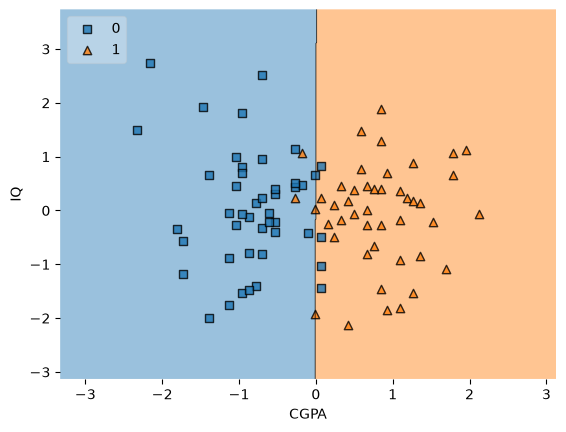

In [173]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X_train, y_train.values, clf=clf, legend=2)

# Adding axes annotations
plt.xlabel('CGPA')
plt.ylabel('IQ')
plt.show()

findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Generic fa

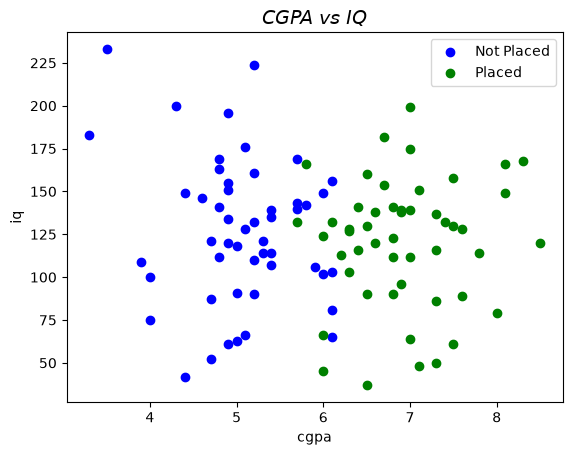

In [174]:
plt.title('CGPA vs IQ', fontfamily='cursive', fontsize=14, fontstyle='italic')
plt.scatter(df[df['placement'] == 0]['cgpa'], df[df['placement'] == 0]['iq'], color='blue', label='Not Placed')
plt.scatter(df[df['placement'] == 1]['cgpa'], df[df['placement'] == 1]['iq'], color='green', label='Placed')

plt.xlabel('cgpa')
plt.ylabel('iq')
plt.legend()
plt.show()

In [175]:
import pickle
pickle.dump(clf, open('model.pkl', 'wb'))
pickle.dump(scaler, open('scaler.pkl', 'wb'))